# Decision Trees

In this notebook, I will use Decision Trees to predict whether a player will reach 'Expert' status, or will a player 'plateau'. I will use a chess training dataset, which includes training data of 45,000 chess players, including games played, training hours, age started and others. I will analyse which factor causes a player to improve in chess, and which factors cause a player to stagnate no matter how many games they play.

Scikit learn uses an optimised CART algorithm to generate decision trees. Entropy (gini impurity) is 0.0 when a node is certain of an outcome, and 0.5 if it's 50/50.

First, import the CSV:

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

print("Imports successful")
csv = pd.read_csv('chess_rating_plateau.csv')
print("Read CSV successful")
SEED = 42

Imports successful
Read CSV successful


## Get Tree

Before generating any trees, I will drop any redundant or useless data from the dataset. 'Reached_expert' and 'plateaued' are dropped as we are trying to predict those. Player_ID, peak_rating, age_now and deliberate_hours are useless or redundant data that is also dropped.

I will then split the remaining dataset into train and test sets. The train set will be used to train the model, while the test set will evaluate the model's performance and  detect overfitting.

I run a GridSearchCV, which exhaustively generates a tree for all depths in `max_depth` and all items in `min_samples_leaf`. Each tree is trained and then fitted on the test set. The best scored tree is then selected automatically. In the example below, 32 trees are generated and the best one is chosen. After selecting the tree, I print the best tree's parameters, classification report, confusion matrix, precision recall curve and feature importances.

In [8]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

drop = ["player_id", "peak_rating", "plateaued", "reached_expert", "deliberate_hours", "age_now"]
features = [c for c in csv.columns if c not in drop]
X = csv[features]

def get_tree(target):
    y = csv[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

    grid = GridSearchCV(
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": range(2, 10), "min_samples_leaf": [5, 10, 25, 50]},
        cv=5, scoring="f1", n_jobs=-1)
    grid.fit(X_train, y_train)
    best = grid.best_estimator_

    print('Best parameters:', grid.best_params_)
    print(classification_report(y_test, best.predict(X_test)))
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, ax=ax[0], cmap='Reds')
    ax[0].grid(False)
    ax[0].set_title("Confusion Matrix")
    PrecisionRecallDisplay.from_estimator(best, X_test, y_test, ax=ax[1])
    ax[1].set_title("Precision Recall Curve")
    plt.show()

    print('Feature importances:')
    print(pd.Series(best.feature_importances_, index=features).sort_values(ascending=False))
    return best

## Expert Decision Tree

A decision tree for predicting whether a player has reached expert has been generated. The best tree's parameters were a depth of 9 and at least 25 samples in each leaf.

The scores for predicting an expert are:
- precision - 0.72
- recall - 0.64
- f1-score - 0.68

This means that the tree can predict an expert reasonably well, but there can be a considerable amount of false negatives. The precision and recall scores of predicting a non-expert are much higher (0.91 and 0.94 respectively), however I want to predict experts, not non experts.

The confusion matrix shows the true vs predicted scores in visual format, while the precision recall curve shows the maximum possible values of precision and recall for any decision tree. The Average Precision (AP) is 0.75.

### Results
Feature importances are printed below the graphs. We can observe that games played, cognitive ability, and tactics training hours are the most important factors in whether a player reaches expert level. Starting age plays a much smaller role in determining expert players. Total study hours, opening study hours and studies endgames have a tiny, almost negligible impact on determining whether a player reaches expert level. This proves that spending many hours on training does not automatically mean that the player reaches expert. To improve, training must be spent on tactics rather than on memorising openings and endgames. Years playing and having a coach are also negligible.

Best parameters: {'max_depth': 9, 'min_samples_leaf': 25}
              precision    recall  f1-score   support

           0       0.91      0.94      0.93      7200
           1       0.72      0.64      0.68      1800

    accuracy                           0.88      9000
   macro avg       0.82      0.79      0.80      9000
weighted avg       0.87      0.88      0.88      9000



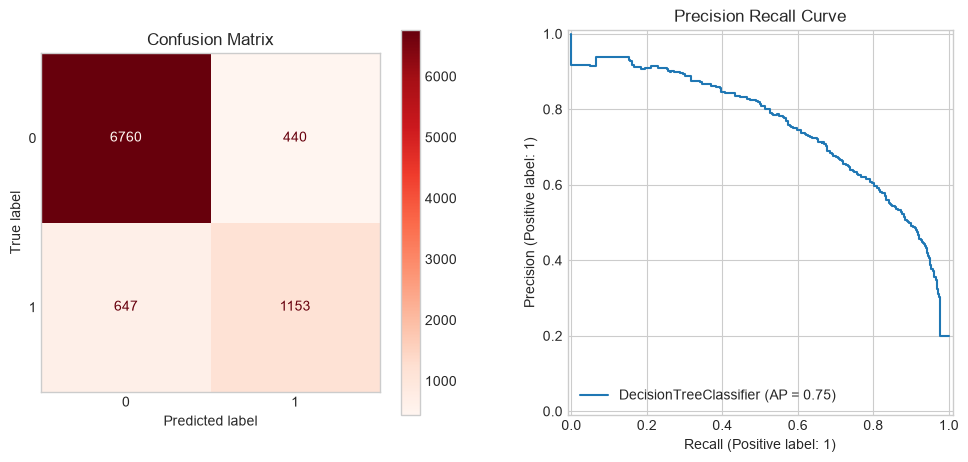

Feature importances:
games_played              0.269525
cognitive_ability         0.252705
tactics_training_hours    0.201043
deliberate_share          0.120941
starting_age              0.090770
analyzes_own_games        0.046971
total_study_hours         0.013467
years_playing             0.002339
opening_study_hours       0.001376
has_coach                 0.000841
studies_endgames          0.000022
dtype: float64


In [9]:
expert_tree = get_tree("reached_expert")

## Plateaued Decision Tree

A decision tree for predicting whether a player has plateaued or not has been generated. The best tree's parameters were a depth of 6 and at least 50 samples in each leaf.

The scores for predicting a plateaued player are:
- precision - 0.55
- recall - 0.33
- f1-score - 0.41

Such low scores mean that this tree is very bad at predicting plateaued players. The confusion matrix tells us that there is almost 2x more false negatives than correctly predicted positives. There is also a large amount of false positives. The precision and recall scores for predicting non-plateaued players are considerably higher, yet they are of no use in this case.

The precision recall curve is very low, the optimal perfect tree is at (1,1), and the closer the curve is, the better. The Average Precision is only 0.5, meaning that no matter how many trees are generated, they will all be very weak at predicting plateaued players.

### Results
The most important features in trying to determine a plateaued player are deliberate share (percentage of training being useful), games played, years playing, and analyses own games. Training hours have negligible to no impact on determining a plateaued player. This could mean that players who plateau spend play thousands of games over many years, but don't train much or most of their training is meaningless. The visual tree below tells us that less than 40% deliberate share of training is a high factor in plateauing.

The tree fails to predict plateaued players accurately as there may be other factors not in the dataset that impact on a player's ability to improve at chess.

Best parameters: {'max_depth': 6, 'min_samples_leaf': 50}
              precision    recall  f1-score   support

           0       0.66      0.83      0.73      5505
           1       0.55      0.33      0.41      3495

    accuracy                           0.63      9000
   macro avg       0.60      0.58      0.57      9000
weighted avg       0.62      0.63      0.61      9000



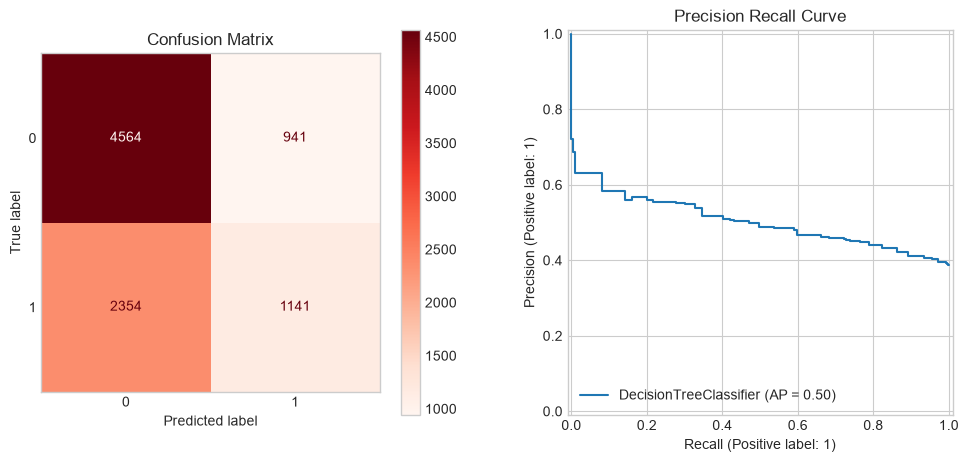

Feature importances:
deliberate_share          0.425767
games_played              0.290910
years_playing             0.158561
analyzes_own_games        0.104860
cognitive_ability         0.005825
opening_study_hours       0.004521
starting_age              0.004192
total_study_hours         0.002720
has_coach                 0.001661
studies_endgames          0.000983
tactics_training_hours    0.000000
dtype: float64


In [10]:
plateaued_tree = get_tree("plateaued")

## Tree Graphs

The code below will save the decision trees as SVG files, allowing you to browse the tree yourself. The darker the colour of each node/leaf, the more certain the prediction is.

In [28]:
plt.figure(figsize=(100, 20))
plot_tree(plateaued_tree, feature_names=features, class_names=["Not plateaued", "Plateaued"], filled=True)
plt.savefig("plateaued_tree.svg", bbox_inches='tight')
plt.close()

In [29]:
plt.figure(figsize=(450, 45))
plot_tree(expert_tree, feature_names=features, class_names=["Non-expert", "Expert"], filled=True)
plt.savefig("expert_tree.svg", bbox_inches='tight')
plt.close()

In [30]:
plt.figure(figsize=(100, 20))
plot_tree(expert_tree, feature_names=features, class_names=["Non-expert", "Expert"], filled=True, max_depth=5)
plt.savefig("expert_tree_truncated.svg", bbox_inches='tight')
plt.close()

## Conclusion

Decision Trees are a simple yet useful classifier algorithm, if properly tuned. GridSearchCV is very useful in finding the best tree given a range of possible trees. Trees were used to predict the likelihood of a player becoming an expert, or plateauing.

### Expert results:
The tree to predict an expert player was reasonably accurate, and it told us that training hours on tactics, amount of games played and cognitive ability were the biggest factors. Meanwhile, spending many hours on memorising openings and endgames proved to have little impact. Starting to play chess when younger may also increase chances of becoming expert, same goes for analysing your own games meaningfully.

### Plateaued results:
Trying to predict will a player plateau is almost impossible with the current dataset and very inaccurate. There seems to be no single factor or combination of factors that can definitively predict a plateaued player. The most important factors are games played and deliberate share. This could mean that players who plateau play thousands of games and spend many hours training do not automatically become experts. The training has to be meaningful and deliberate, rather than memorising openings and endgames.

There can also be other factors in life that could prevent a player from improving in chess not covered by this dataset and therefore the trees.